# 10 · Features, matching, and image registration

**Level:** Intermediate  
**Prerequisites:** Notebooks 01–09; grayscale, coordinates, and homographies.

## What you will build and learn

- Detect ORB keypoints and describe local appearance.
- Match binary descriptors with Hamming distance and a ratio test.
- Reject outliers with RANSAC.
- Evaluate an estimated homography against known geometry.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Create a textured planar target
Feature registration needs distinctive local texture. Blank walls and repeated tiles are difficult. We generate many reproducible marks, then apply a known homography. This gives ground truth without internet images. A homography is appropriate because our target is a single plane.


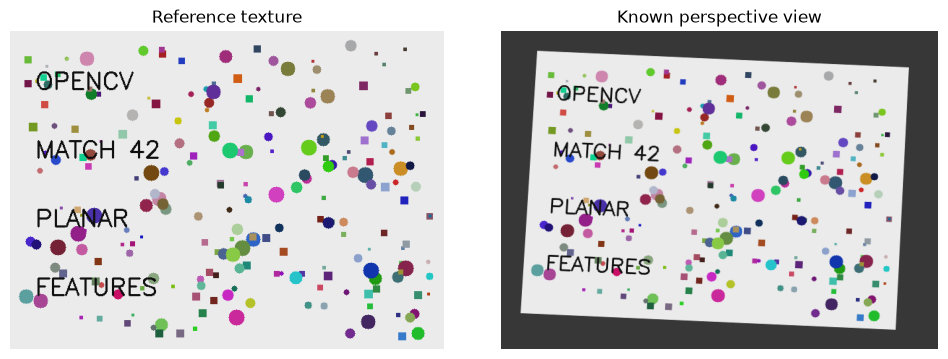

In [2]:
texture = np.full((440, 600, 3), 235, np.uint8)
for i in range(220):
    x, y = rng.integers([18, 18], [582, 422])
    color = tuple(int(v) for v in rng.integers(15, 210, 3))
    radius = int(rng.integers(3, 12))
    if i % 2:
        cv2.circle(texture, (int(x), int(y)), radius, color, -1)
    else:
        cv2.rectangle(texture, (int(x), int(y)), (int(x + radius), int(y + radius)), color, -1)
for i, label in enumerate(['OPENCV', 'MATCH 42', 'PLANAR', 'FEATURES']):
    cv2.putText(texture, label, (35, 80 + i * 95), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (15, 15, 15), 2)
h, w = texture.shape[:2]
corners = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
target_corners = np.float32([[55, 30], [615, 55], [595, 450], [30, 425]])
H_true = cv2.getPerspectiveTransform(corners, target_corners)
target = cv2.warpPerspective(texture, H_true, (660, 480), borderValue=(55, 55, 55))
show_images([texture, target], ['Reference texture', 'Known perspective view'], cols=2)


In [3]:
gray1 = cv2.cvtColor(texture, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(target, cv2.COLOR_BGR2GRAY)
print('Reference dimensions:', gray1.shape, '| target dimensions:', gray2.shape)
assert np.linalg.det(H_true) != 0


Reference dimensions: (440, 600) | target dimensions: (480, 660)


## Step 2 — Detect keypoints and compute ORB descriptors
A keypoint stores position, scale, orientation, and response. A descriptor summarizes its local appearance. ORB descriptors are binary; use Hamming distance. `nfeatures` caps the retained features, while `fastThreshold` changes corner sensitivity. More keypoints can increase cost and include weak evidence.


Keypoints: 1800 1800
Descriptor arrays: (1800, 32) (1800, 32) uint8


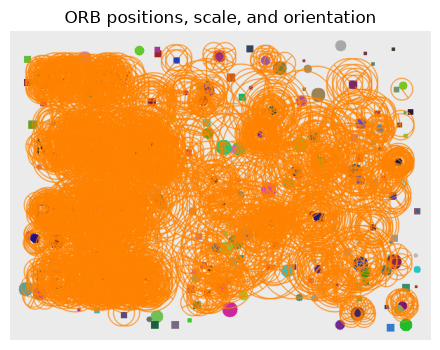

In [4]:
orb = cv2.ORB_create(nfeatures=1800, fastThreshold=12)
kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)
if des1 is None or des2 is None:
    raise RuntimeError('No descriptors. Add texture or reduce the detector threshold.')
print('Keypoints:', len(kp1), len(kp2))
print('Descriptor arrays:', des1.shape, des2.shape, des1.dtype)
keypoint_view = cv2.drawKeypoints(texture, kp1, None, color=(0, 130, 255),
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show_images([keypoint_view], ['ORB positions, scale, and orientation'])


In [5]:
for threshold in [5, 20, 60]:
    probe = cv2.ORB_create(nfeatures=1800, fastThreshold=threshold)
    keypoints, descriptors = probe.detectAndCompute(gray1, None)
    print(f'fastThreshold={threshold:2}: {len(keypoints)} keypoints')
blank_kp, blank_des = orb.detectAndCompute(np.full_like(gray1, 150), None)
print('Uniform-image keypoints:', len(blank_kp), '| descriptors:', blank_des)
assert blank_des is None, 'A blank image should not provide useful ORB features.'


fastThreshold= 5: 1800 keypoints
fastThreshold=20: 1798 keypoints


fastThreshold=60: 1758 keypoints
Uniform-image keypoints: 0 | descriptors: None


## Step 3 — Match descriptors and reject ambiguity
For every reference descriptor, `knnMatch(k=2)` finds the two closest candidates in the target. Keep the best only when its distance is less than `ratio × second_best`. A smaller ratio is stricter. This is an ambiguity filter, not a probability. Some queries can have fewer than two neighbors: guard that case.


Queries: 1800 | after ratio test: 569


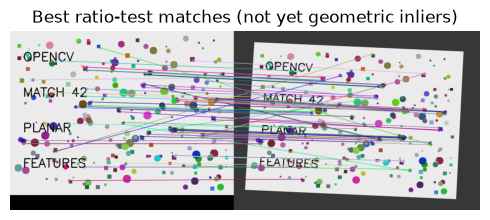

In [6]:
matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
neighbors = matcher.knnMatch(des1, des2, k=2)

def ratio_filter(knn_matches, ratio=.75):
    return [pair[0] for pair in knn_matches
            if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]

good = ratio_filter(neighbors, .75)
print('Queries:', len(neighbors), '| after ratio test:', len(good))
match_view = cv2.drawMatches(texture, kp1, target, kp2,
                            sorted(good, key=lambda m: m.distance)[:70], None,
                            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show_images([match_view], ['Best ratio-test matches (not yet geometric inliers)'])


In [7]:
for ratio in [.55, .7, .8, .9]:
    candidates = ratio_filter(neighbors, ratio)
    print(f'ratio={ratio:.2f}: {len(candidates)} candidate matches')
assert len(ratio_filter(neighbors, .55)) <= len(ratio_filter(neighbors, .9))


ratio=0.55: 213 candidate matches
ratio=0.70: 481 candidate matches
ratio=0.80: 695 candidate matches
ratio=0.90: 1006 candidate matches


## Step 4 — Estimate a homography with RANSAC
At least four suitable point pairs are required, but more distributed matches are safer. RANSAC repeatedly fits small samples and seeks a transformation supported by many pairs. `ransacReprojThreshold=3` allows about 3 target-image pixels of reprojection error. The returned inlier mask aligns with the input match list.


In [8]:
def estimate_homography(matches, threshold=3.0):
    if len(matches) < 4:
        return None, None
    source_points = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    target_points = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, inliers = cv2.findHomography(source_points, target_points, cv2.RANSAC, threshold)
    if H is None or inliers is None or not np.isfinite(H).all():
        return None, None
    return H, inliers.ravel().astype(bool)

cv2.setRNGSeed(42)
H_est, inlier_mask = estimate_homography(good)
if H_est is None:
    raise RuntimeError('Homography estimation failed. Inspect texture, matches, and point distribution.')
print(f'RANSAC inliers: {inlier_mask.sum()} / {len(good)} ({inlier_mask.mean():.1%})')
assert inlier_mask.sum() >= 4
assert estimate_homography(good[:3]) == (None, None)


RANSAC inliers: 511 / 569 (89.8%)


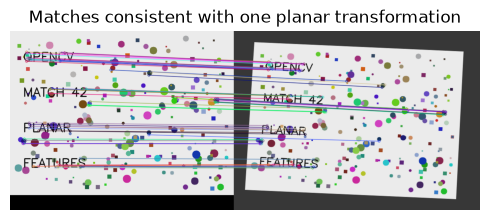

In [9]:
inlier_matches = [m for m, keep in zip(good, inlier_mask) if keep]
verified_view = cv2.drawMatches(texture, kp1, target, kp2, inlier_matches[:65], None,
                               flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show_images([verified_view], ['Matches consistent with one planar transformation'])


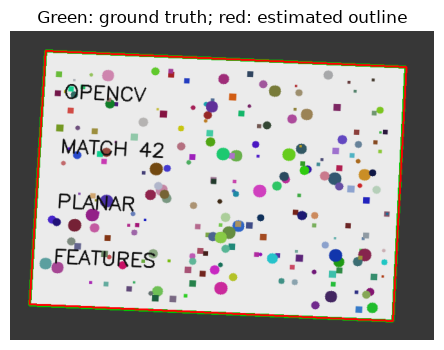

Corner errors in pixels: [0.28  0.783 0.467 0.61 ]


In [10]:
estimated_corners = cv2.perspectiveTransform(corners[None], H_est)[0]
true_corners = cv2.perspectiveTransform(corners[None], H_true)[0]
errors = np.linalg.norm(estimated_corners - true_corners, axis=1)
outline = target.copy()
cv2.polylines(outline, [np.rint(true_corners).astype(np.int32)], True, (0, 200, 0), 4)
cv2.polylines(outline, [np.rint(estimated_corners).astype(np.int32)], True, (0, 0, 255), 2)
show_images([outline], ['Green: ground truth; red: estimated outline'])
print('Corner errors in pixels:', np.round(errors, 3))
assert errors.mean() < 8, 'Large synthetic corner error: inspect match consistency.'


Compare mapped points, not raw matrix entries: homographies have an arbitrary multiplicative scale. Also inspect spatial coverage. Twenty inliers in one small corner can extrapolate poorly to the rest of the document.


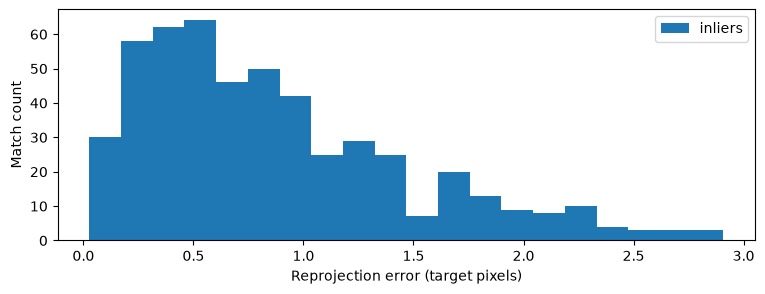

Median inlier residual: 0.7140929102897644


In [11]:
src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
projected = cv2.perspectiveTransform(src, H_est)
residuals = np.linalg.norm(projected - dst, axis=2).ravel()
plt.figure(figsize=(9, 3))
plt.hist(residuals[inlier_mask], bins=20, label='inliers')
plt.xlabel('Reprojection error (target pixels)'); plt.ylabel('Match count'); plt.legend(); plt.show()
print('Median inlier residual:', float(np.median(residuals[inlier_mask])))


## Step 5 — Mini-project: align a photographed label
Warp the target back into reference coordinates using the inverse estimated homography. Evaluate within the target's valid image footprint. Synthetic ground truth enables a real error measurement; in real data you would hold out verified correspondences or inspect downstream task performance.


Valid-region MAE: 2.8070732616631053


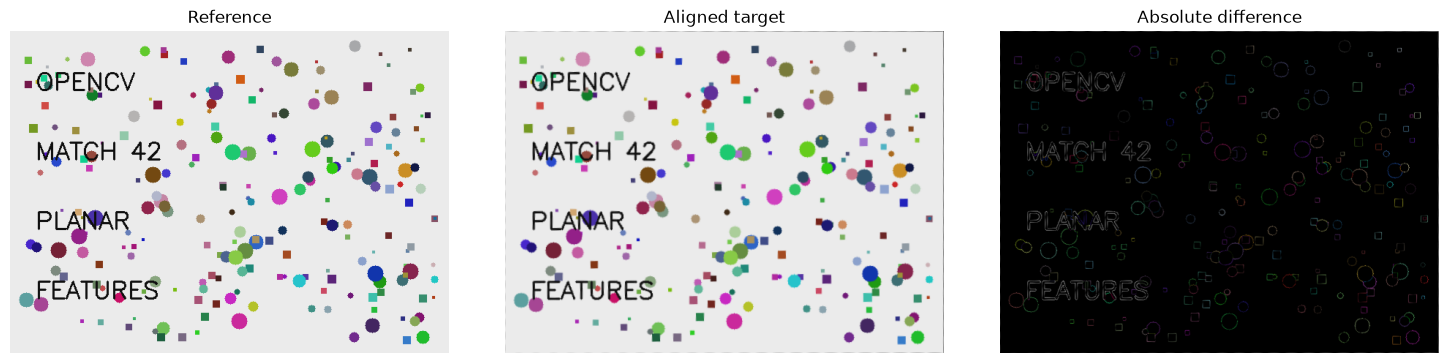

In [12]:
aligned = cv2.warpPerspective(target, np.linalg.inv(H_est), (w, h))
valid_target = np.full(gray2.shape, 255, np.uint8)
valid = cv2.warpPerspective(valid_target, np.linalg.inv(H_est), (w, h), flags=cv2.INTER_NEAREST) > 0
valid[:12] = False; valid[-12:] = False; valid[:, :12] = False; valid[:, -12:] = False
diff = cv2.absdiff(texture, aligned)
print('Valid-region MAE:', float(diff[valid].mean()))
show_images([texture, aligned, diff], ['Reference', 'Aligned target', 'Absolute difference'])


In [13]:
out_dir = ROOT / 'outputs' / '10_registration'
out_dir.mkdir(parents=True, exist_ok=True)
save_image(out_dir / 'aligned_label.png', aligned)
save_image(out_dir / 'estimated_outline.png', outline)
np.save(out_dir / 'reference_to_target_H.npy', H_est)
print('Saved registration artifacts to', out_dir)


Saved registration artifacts to C:\Users\Hareram ray\AI\OpencvPractical\outputs\10_registration


### Pitfalls and practice
- ORB uses Hamming; standard float descriptors such as SIFT normally use L2. Mixing them gives meaningless comparisons.
- `queryIdx` indexes the reference descriptors and `trainIdx` indexes the target descriptors in this call.
- A large match count does not guarantee correct registration; inspect inlier rate, coverage, and geometric error.
- Parallax, repetitive textures, strong blur, and non-planar objects can defeat a single homography.

1. Try ratio thresholds .6, .75, and .9. Report matches, inliers, and mean corner error.
2. Compare RANSAC thresholds 1, 3, and 8 pixels with the same matches.
3. Explain why an empty descriptor set must be handled before calling the matcher.


## Worked solutions
The loosest threshold may produce more inliers while accepting less accurate correspondences. Evaluate the desired geometry as well as counts.


In [14]:
for ratio in [.6, .75, .9]:
    candidate_matches = ratio_filter(neighbors, ratio)
    H_candidate, candidate_inliers = estimate_homography(candidate_matches)
    if H_candidate is None:
        print(ratio, 'insufficient or degenerate matches')
        continue
    candidate_corners = cv2.perspectiveTransform(corners[None], H_candidate)[0]
    corner_mae = np.linalg.norm(candidate_corners - true_corners, axis=1).mean()
    print(f'ratio={ratio:.2f}, matches={len(candidate_matches)}, inliers={candidate_inliers.sum()}, corner error={corner_mae:.3f}px')


ratio=0.60, matches=289, inliers=274, corner error=0.333px
ratio=0.75, matches=569, inliers=511, corner error=0.535px
ratio=0.90, matches=1006, inliers=756, corner error=0.778px


In [15]:
for threshold in [1.0, 3.0, 8.0]:
    H_candidate, candidate_inliers = estimate_homography(good, threshold)
    if H_candidate is None:
        print(threshold, 'estimation failed')
        continue
    candidate_corners = cv2.perspectiveTransform(corners[None], H_candidate)[0]
    error = np.linalg.norm(candidate_corners - true_corners, axis=1).mean()
    print(f'RANSAC threshold={threshold:.1f}px, inliers={candidate_inliers.sum()}, corner error={error:.3f}px')
print('None descriptors mean there are no descriptor rows to compare; return a clear no-match result.')


RANSAC threshold=1.0px, inliers=304, corner error=2.098px
RANSAC threshold=3.0px, inliers=511, corner error=0.535px
RANSAC threshold=8.0px, inliers=533, corner error=0.381px
None descriptors mean there are no descriptor rows to compare; return a clear no-match result.


### Reflection
Explain why descriptor matching and geometric verification solve different problems. What would be a trustworthy failure signal for a real label scanner?

Official references: [ORB](https://docs.opencv.org/4.x/d1/d89/tutorial_py_orb.html), [Matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html), [Feature matching and homography](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html).
